# Evidencia ML: integridad declarada bajo mutaciones controladas

Este notebook reproduce una **simulación sintética**, no datos de producción. La unidad es un bundle JSON con tres artefactos (dataset, modelo y aprobación); 40 copias deterministas por escenario comprueban reproducibilidad del fixture, no incertidumbre poblacional.

Hipótesis preregistrada en `config.json`: aceptar todos los controles limpios y rechazar todas las corrupciones ocurridas después de fijar el manifiesto (payload modificado/ausente, dependencia faltante y ciclo). El control auto-rehash es negativo: manifiesto y contenido se reescriben en conjunto.


In [2]:
from pathlib import Path
import csv, json
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd()
if ROOT.name != 'mvp-evidence-integrity':
    ROOT = next(p for p in Path.cwd().parents for p in [p / '05-artificial-intelligence-and-computational-systems/08-ai-reliability-security-and-governance/02-ml-governance-evidence-ledger/mvp-evidence-integrity'] if p.exists())
raw = pd.read_csv(ROOT / 'results/raw_cases.csv')
summary = json.loads((ROOT / 'results/summary.json').read_text())
display(pd.DataFrame(summary['summary']))


,mode,n,baseline_accept,hash_only_accept,full_accept,expected_accept
0,clean,40,40,40,40,40
1,payload_tamper,40,40,0,0,0
2,missing_payload,40,40,0,0,0
3,missing_dependency,40,40,40,0,0
4,cycle,40,40,40,0,0
5,rehash_after_tamper,40,40,40,40,0


## Algoritmos y costo

Baseline: valida que exista el manifiesto y que el conjunto de tipos declarados cubra los requeridos. Ablación hash-only: además recalcula SHA-256 de cada payload. Método completo: hash + forma + unicidad de IDs + rutas confinadas + tipos requeridos + referencias de dependencia + ausencia de ciclos. Con V artefactos, E relaciones y B bytes, el recorrido del grafo cuesta O(V+E) tiempo/espacio y la lectura/hash cuesta O(B). La clave de decisión es aceptación iff no hay hallazgos.

Para cada modo, aceptación = bundles aceptados / bundles del modo. Sensibilidad del fixture = rechazos entre las cuatro clases ex-post / total de esas filas. Especificidad operativa del fixture = aceptaciones en limpio / 40. Estos cocientes son descriptivos del generador determinista; no se interpretan como tasas reales de seguridad.


In [4]:
def rates(df):
    return df.groupby('mode')[['baseline_valid','hash_only_valid','full_valid','expected_valid']].mean().round(3)
rates_table = rates(raw)
display(rates_table)
ex_post = raw[raw['mode'].isin(['payload_tamper','missing_payload','missing_dependency','cycle'])]
print('Ex-post mutation rejection, full verifier:', round(1-ex_post.full_valid.mean(), 3))
print('Clean acceptance, full verifier:', round(raw[raw['mode']=='clean'].full_valid.mean(), 3))


Ex-post mutation rejection, full verifier: 1.0
Clean acceptance, full verifier: 1.0


,baseline_valid,hash_only_valid,full_valid,expected_valid
mode,,,,
clean,1.0,1.0,1.0,1.0
cycle,1.0,1.0,0.0,0.0
missing_dependency,1.0,1.0,0.0,0.0
missing_payload,1.0,0.0,0.0,0.0
payload_tamper,1.0,0.0,0.0,0.0
rehash_after_tamper,1.0,1.0,1.0,0.0


## Ablación y resultado negativo

El baseline deja pasar corrupción porque no comprueba payload ni relaciones. Hash-only sí detecta cambios y faltantes de bytes, pero no referencias huérfanas ni ciclos. El grafo completo cubre esos errores estructurales. Sin embargo, cuando el atacante reemplaza el payload y recalcula el hash dentro del mismo manifiesto, la verificación completa acepta. Esto no es un fallo inesperado del SHA-256: falta una raíz de confianza independiente que fije la expectativa.


Acceptances in the rehash negative control (of 40):


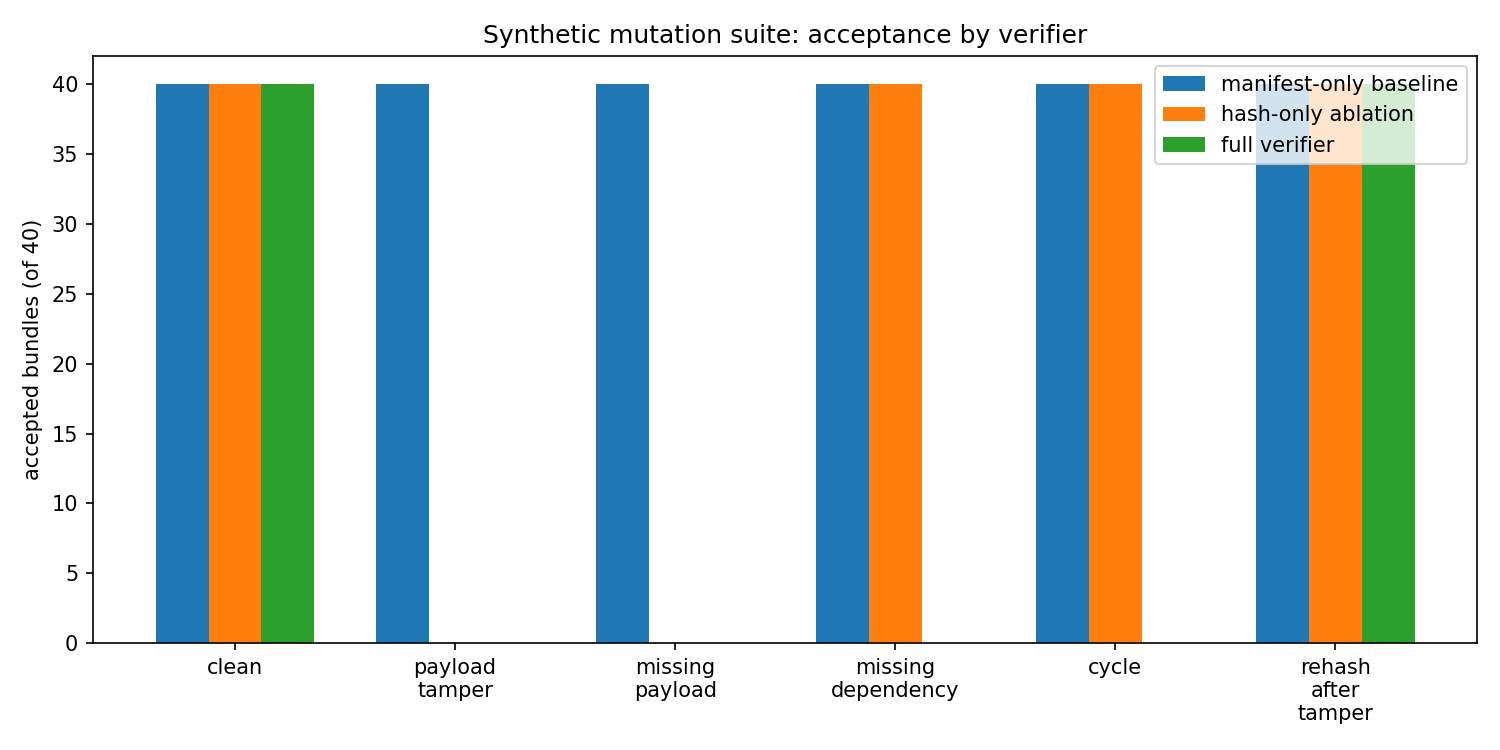

,accepted
baseline_valid,40
hash_only_valid,40
full_valid,40


In [6]:
display(Image(filename=str(ROOT/'results/acceptance.png')))
negative = raw[raw['mode']=='rehash_after_tamper'][['baseline_valid','hash_only_valid','full_valid']].sum()
print('Acceptances in the rehash negative control (of 40):')
display(negative.to_frame('accepted'))


## Decisión

El prototipo satisface las compuertas sobre cuatro mutaciones posteriores a la fijación del manifiesto: 160/160 rechazadas, y acepta 40/40 limpios. El resultado no da seguridad frente a control del manifiesto, falsedad de los datos declarados, insider malicioso o CI comprometido. Para ese salto hace falta validar firma, identidad de builder y política desde un root-of-trust externo, como plantean SLSA/in-toto/TUF; el MVP no implementa esa capa y no debe autorizar despliegues.

Clasificación de madurez: código, tests y simulación reproducible (M2/prototipo verificado). No validado: no hay corpus externo, evaluación independiente ni pipeline real. No operacional: no hay claves, permisos, auditoría de servicio ni SLO.
